<a href="https://colab.research.google.com/github/siyaagarwal2005/sepsis-prediction-using-LSTM/blob/main/3_sequence_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook III — Sequence Engineering

---

**Project:** AI-Based Sepsis Early Warning System  
**Dataset:** PhysioNet Challenge 2019  
**Author:** *Siya Agarwal*  
**Date:** *05 March, 2026*

---

### Purpose
Convert the preprocessed flat tabular data into 3D sequences that an LSTM can consume.

An LSTM does not take rows as input. It takes **windows of time** — a block of consecutive hours — and learns the temporal pattern within that window. This notebook builds those windows.

### The Core Transformation
```
Input  : (1,241,768 rows) × (15 features)       — flat 2D table
Output : (n_sequences)   × (6 hours) × (15 features) — 3D tensor
```

### Inputs
- `/content/drive/MyDrive/sepsis_project/processed_data/train_processed.csv`
- `/content/drive/MyDrive/sepsis_project/processed_data/test_processed.csv`

### Outputs
- `processed_data/X_train.npy`, `y_train.npy`
- `processed_data/X_test.npy`, `y_test.npy`

### Key Design Decision — Window Size = 6
We use a 6-hour sliding window. At each hour `t`, the model sees hours `[t-6 … t-1]`
and predicts whether sepsis will occur at hour `t`.
This gives clinicians a **6-hour warning window** — enough time for antibiotics,
fluids, and intervention before organ failure begins.

### Next Notebook
- `IV_model_training.ipynb` — LSTM architecture, training, class imbalance handling

---
## Section 0 — Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display

# ── Project paths ──────────────────────────────────────────────────────────────
BASE_PATH      = '/content/drive/MyDrive/sepsis_project/'
PROCESSED_PATH = BASE_PATH + 'processed_data/'

# ── Sequence engineering hyperparameter ───────────────────────────────────────
# WINDOW_SIZE = 6 means: look at 6 consecutive ICU hours → predict sepsis risk
# at the next hour. This aligns with the 6-hour clinical intervention window.
WINDOW_SIZE = 6

# ── Feature columns (15 features — Patient_ID and SepsisLabel are excluded) ───
FEATURE_COLS = [
    'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp',
    'Lactate', 'WBC', 'Creatinine', 'BUN', 'pH',
    'Age', 'Gender', 'ICULOS'
]

print('Setup complete.')
print(f'Window size    : {WINDOW_SIZE} hours')
print(f'Feature count  : {len(FEATURE_COLS)}')

Setup complete.
Window size    : 6 hours
Feature count  : 15


---
## Section 1 — Load Preprocessed Data

We load the clean, scaled, split data produced by `II_preprocessing.ipynb`.
No imputation or scaling happens here — that was done in Notebook II.
This notebook only does one thing: reshape data into sequences.

In [ ]:
df_train = pd.read_csv(PROCESSED_PATH + 'train_processed.csv')
df_test  = pd.read_csv(PROCESSED_PATH + 'test_processed.csv')

print('=== Loaded Data ===')
print(f'Train shape : {df_train.shape}')   # expect (~1.24M rows, 17 cols)
print(f'Test  shape : {df_test.shape}')    # expect (~310K rows, 17 cols)
print(f'\nColumns     : {list(df_train.columns)}')
print(f'\nNaNs in train: {df_train.isnull().sum().sum()}')   # must be 0
print(f'NaNs in test : {df_test.isnull().sum().sum()}')     # must be 0

=== Loaded Data ===
Train shape : (1240596, 17)
Test  shape : (311614, 17)

Columns     : ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Lactate', 'WBC', 'Creatinine', 'BUN', 'pH', 'Age', 'Gender', 'ICULOS', 'Patient_ID', 'SepsisLabel']

NaNs in train: 0
NaNs in test : 0


---
## Section 2 — Understanding Sequence Engineering

Before writing any code, it helps to understand exactly what we're building.

### What does the LSTM receive as input?
A single training sample looks like this:

```
X[i] = [
    [HR_t-5, O2Sat_t-5, Temp_t-5, ...],   ← hour t-5
    [HR_t-4, O2Sat_t-4, Temp_t-4, ...],   ← hour t-4
    [HR_t-3, O2Sat_t-3, Temp_t-3, ...],   ← hour t-3
    [HR_t-2, O2Sat_t-2, Temp_t-2, ...],   ← hour t-2
    [HR_t-1, O2Sat_t-1, Temp_t-1, ...],   ← hour t-1
    [HR_t,   O2Sat_t,   Temp_t,   ...],   ← hour t
]   → shape: (6, 15)

y[i] = SepsisLabel at hour t+1   ← what we're predicting
```

### The sliding window mechanism
For a patient with 40 ICU hours, we generate:
- Window 1: hours [1–6]   → predict hour 7
- Window 2: hours [2–7]   → predict hour 8
- Window 3: hours [3–8]   → predict hour 9
- ...
- Window 34: hours [34–39] → predict hour 40

That's `40 - 6 = 34` sequences from one patient.  
A patient with only 8 ICU hours produces `8 - 6 = 2` sequences.

### Critical rule — sequences never cross patient boundaries
We generate windows **per patient**. The last hour of Patient A never
connects to the first hour of Patient B. Mixing patients would create
biologically meaningless sequences.

---
## Section 3 — Sequence Generation Function

The function below slides a window of size `WINDOW_SIZE` across each patient's
timeline and collects:
- `X`: the feature values in the window — shape `(window_size, n_features)`
- `y`: the SepsisLabel at the step **immediately after** the window ends

This is repeated for every valid window position across every patient.

In [ ]:
def create_sequences(df, feature_cols, label_col='SepsisLabel',
                     patient_col='Patient_ID', window=6):
    """
    Convert a flat patient-hour dataframe into LSTM-ready sequences.

    Parameters
    ----------
    df          : DataFrame sorted by patient and time (from Notebook II)
    feature_cols: list of feature column names (excludes Patient_ID, SepsisLabel)
    label_col   : target column name
    patient_col : column used to group by patient
    window      : number of consecutive hours per sequence

    Returns
    -------
    X : np.ndarray of shape (n_sequences, window, n_features)
    y : np.ndarray of shape (n_sequences,)
    """
    X_list, y_list = [], []

    for pid, group in df.groupby(patient_col):
        # Extract feature matrix and label vector for this patient
        values = group[feature_cols].values   # shape: (n_hours, n_features)
        labels = group[label_col].values      # shape: (n_hours,)

        # Skip patients who have fewer hours than the window size
        # (they cannot produce even a single valid sequence)
        if len(group) <= window:
            continue

        # Slide window across this patient's timeline
        for i in range(len(group) - window):
            X_list.append(values[i : i + window])   # window of features
            y_list.append(labels[i + window])        # label at next step

    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)


print('Sequence generation function defined.')

Sequence generation function defined.


---
## Section 4 — Generate Sequences

We now apply the function to both train and test sets.

**Expected output shapes:**
- `X_train`: `(~1.2M sequences, 6, 15)` — train sequences
- `X_test` : `(~300K sequences, 6, 15)` — test sequences
- `y_train` / `y_test`: 1D arrays of 0s and 1s

This cell will take **2–5 minutes** to run — it is iterating over 40,000 patients.

In [ ]:
print('Generating training sequences... (this takes a few minutes)')
X_train, y_train = create_sequences(df_train, FEATURE_COLS, window=WINDOW_SIZE)
print(f'Training sequences done.')

print('Generating test sequences...')
X_test, y_test = create_sequences(df_test, FEATURE_COLS, window=WINDOW_SIZE)
print(f'Test sequences done.')

# ── Shape verification ─────────────────────────────────────────────────────────
print('\n=== Sequence Shapes ===')
print(f'X_train : {X_train.shape}')   # expect (~1.2M, 6, 15)
print(f'y_train : {y_train.shape}')   # expect (~1.2M,)
print(f'X_test  : {X_test.shape}')    # expect (~300K, 6, 15)
print(f'y_test  : {y_test.shape}')    # expect (~300K,)

# ── Memory usage ───────────────────────────────────────────────────────────────
mem_mb = (X_train.nbytes + X_test.nbytes + y_train.nbytes + y_test.nbytes) / 1e6
print(f'\nTotal memory used by arrays: {mem_mb:.1f} MB')

Generating training sequences... (this takes a few minutes)
Training sequences done.
Generating test sequences...
Test sequences done.

=== Sequence Shapes ===
X_train : (1046988, 6, 15)
y_train : (1046988,)
X_test  : (263206, 6, 15)
y_test  : (263206,)

Total memory used by arrays: 476.9 MB


---
## Section 5 — Class Imbalance in Sequences

Just as in the raw data, sepsis sequences are the minority class.
We check the label distribution in both generated arrays.

We also compute `class_weight` here — this will be passed directly
to the LSTM during training in Notebook IV to penalise the model
more heavily for missing a sepsis case than for a false alarm.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# ── Label distribution ─────────────────────────────────────────────────────────
train_pos = y_train.sum()
train_neg = len(y_train) - train_pos
test_pos  = y_test.sum()
test_neg  = len(y_test) - test_pos

print('=== Sequence Label Distribution ===')
print(f'Train — Sepsis (1)    : {int(train_pos):,}  ({train_pos/len(y_train)*100:.2f}%)')
print(f'Train — No Sepsis (0) : {int(train_neg):,}  ({train_neg/len(y_train)*100:.2f}%)')
print(f'Test  — Sepsis (1)    : {int(test_pos):,}   ({test_pos/len(y_test)*100:.2f}%)')
print(f'Test  — No Sepsis (0) : {int(test_neg):,}   ({test_neg/len(y_test)*100:.2f}%)')

# ── Compute class weights ──────────────────────────────────────────────────────
# class_weight='balanced' formula: n_samples / (n_classes * n_samples_per_class)
# The result tells the model: "a sepsis prediction error is X times more costly
# than a non-sepsis prediction error."
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
class_weight_dict = {0: weights[0], 1: weights[1]}

print(f'\n=== Class Weights for Training ===')
print(f'Weight for class 0 (no sepsis) : {weights[0]:.4f}')
print(f'Weight for class 1 (sepsis)    : {weights[1]:.4f}')
print(f'\nInterpretation: A missed sepsis prediction is penalised'
      f' ~{weights[1]/weights[0]:.1f}x more than a false alarm.')

=== Sequence Label Distribution ===
Train — Sepsis (1)    : 19,609  (1.87%)
Train — No Sepsis (0) : 1,027,379  (98.13%)
Test  — Sepsis (1)    : 4,794   (1.82%)
Test  — No Sepsis (0) : 258,412   (98.18%)

=== Class Weights for Training ===
Weight for class 0 (no sepsis) : 0.5095
Weight for class 1 (sepsis)    : 26.6966

Interpretation: A missed sepsis prediction is penalised ~52.4x more than a false alarm.


---
## Section 6 — Visualise a Single Sequence

Before saving anything, we inspect one actual sequence to confirm the
data looks physiologically sensible. Printing raw arrays is not enough —
plotting reveals patterns a table cannot.

We pick one sepsis-positive sequence and plot all 15 features across its 6 hours.

Visualising sequence index: 274
Label (sepsis at next step): 1
Sequence shape: (6, 15)



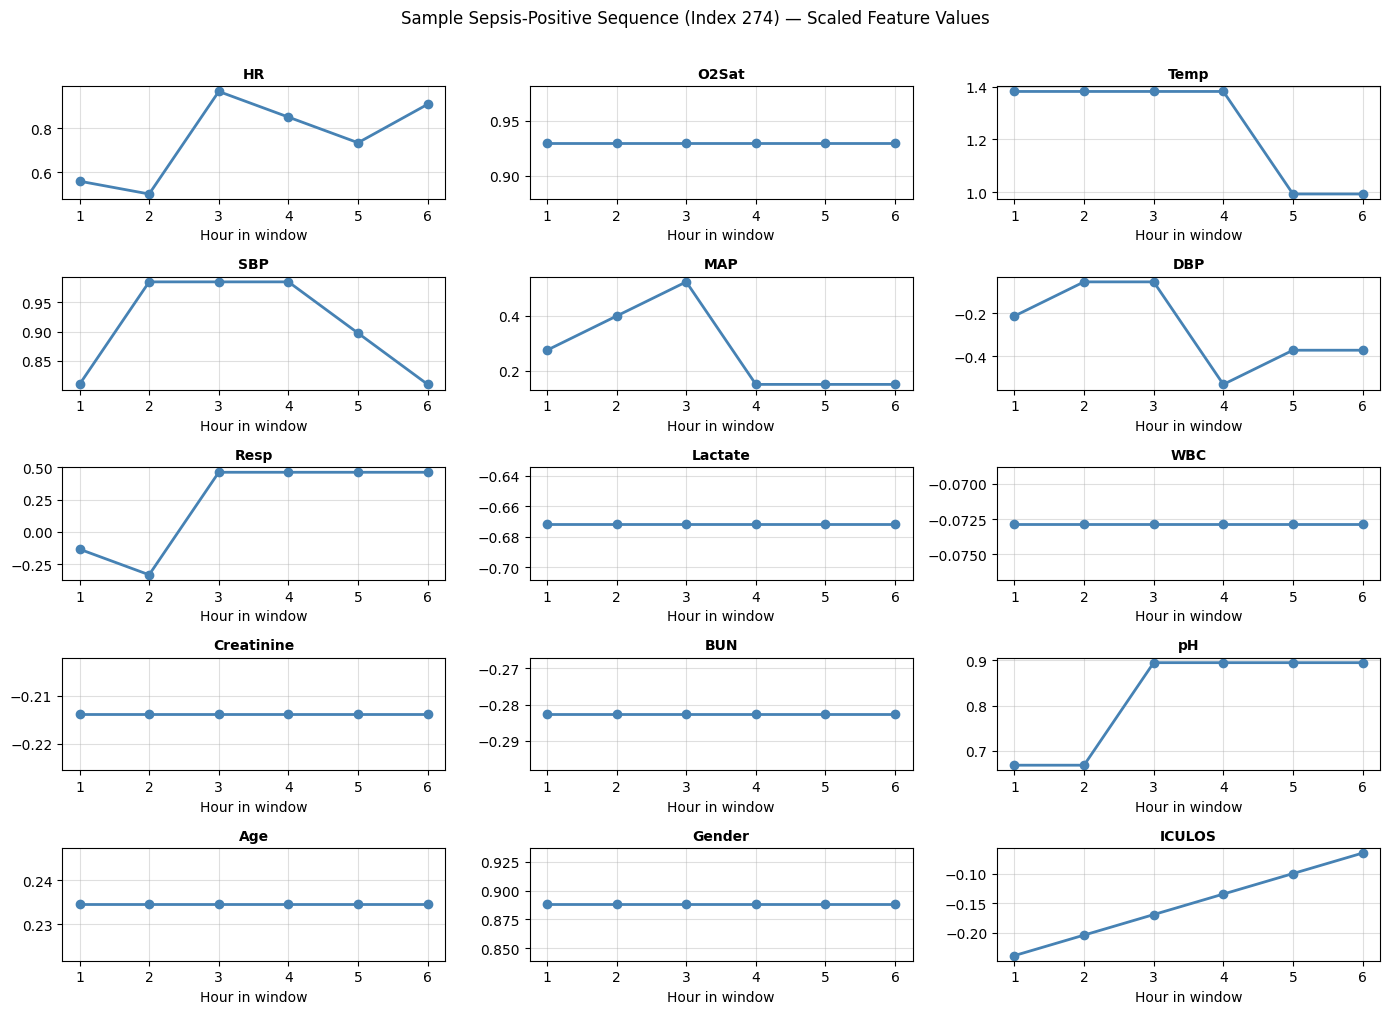

In [ ]:
# ── Find first sepsis-positive sequence in train set ──────────────────────────
sepsis_idx = np.where(y_train == 1)[0][0]
sample_seq = X_train[sepsis_idx]   # shape: (6, 15)

print(f'Visualising sequence index: {sepsis_idx}')
print(f'Label (sepsis at next step): {int(y_train[sepsis_idx])}')
print(f'Sequence shape: {sample_seq.shape}\n')

# ── Plot all 15 features across 6 hours ───────────────────────────────────────
fig, axes = plt.subplots(5, 3, figsize=(14, 10))
axes = axes.flatten()
hours = list(range(1, WINDOW_SIZE + 1))

for i, feat in enumerate(FEATURE_COLS):
    axes[i].plot(hours, sample_seq[:, i], marker='o', linewidth=2, color='steelblue')
    axes[i].set_title(feat, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Hour in window')
    axes[i].set_xticks(hours)
    axes[i].grid(True, alpha=0.4)

plt.suptitle(f'Sample Sepsis-Positive Sequence (Index {sepsis_idx}) — Scaled Feature Values',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

---
## Section 7 — Save Arrays to Google Drive

We save the four numpy arrays to `processed_data/` as `.npy` files.

Why `.npy` instead of CSV?
- 3D arrays cannot be stored in CSV format (CSV is 2D only)
- `.npy` preserves dtype (`float32`) and shape exactly
- Loading `.npy` is ~10x faster than reading a large CSV

Notebook IV loads these files directly with `np.load()`.

In [ ]:
np.save(PROCESSED_PATH + 'X_train.npy', X_train)
np.save(PROCESSED_PATH + 'y_train.npy', y_train)
np.save(PROCESSED_PATH + 'X_test.npy',  X_test)
np.save(PROCESSED_PATH + 'y_test.npy',  y_test)

# Also save class weights so Notebook IV can load them without recomputing
np.save(PROCESSED_PATH + 'class_weights.npy', weights)

print('=== Files Saved to Google Drive ===')
for fname in ['X_train.npy', 'y_train.npy', 'X_test.npy', 'y_test.npy', 'class_weights.npy']:
    fpath = PROCESSED_PATH + fname
    size_mb = os.path.getsize(fpath) / 1e6
    print(f'{fname:<25}: {size_mb:.1f} MB')

=== Files Saved to Google Drive ===
X_train.npy              : 376.9 MB
y_train.npy              : 4.2 MB
X_test.npy               : 94.8 MB
y_test.npy               : 1.1 MB
class_weights.npy        : 0.0 MB


---
## Section 8 — Final Verification

Reload the saved files from disk and confirm shapes and dtypes are intact.
This is a critical check — if the save/load cycle corrupts the data, we catch it
here rather than halfway through a 3-hour training run.

In [ ]:
X_train_check = np.load(PROCESSED_PATH + 'X_train.npy')
y_train_check = np.load(PROCESSED_PATH + 'y_train.npy')
X_test_check  = np.load(PROCESSED_PATH + 'X_test.npy')
y_test_check  = np.load(PROCESSED_PATH + 'y_test.npy')

print('=== Reload Verification ===')
print(f'X_train : shape={X_train_check.shape}, dtype={X_train_check.dtype}')
print(f'y_train : shape={y_train_check.shape}, dtype={y_train_check.dtype}')
print(f'X_test  : shape={X_test_check.shape},  dtype={X_test_check.dtype}')
print(f'y_test  : shape={y_test_check.shape},  dtype={y_test_check.dtype}')

assert X_train_check.shape == X_train.shape, 'Shape mismatch — X_train'
assert X_test_check.shape  == X_test.shape,  'Shape mismatch — X_test'
print('\nAll shapes verified. Sequence engineering complete.')
print('Ready for IV_model_training.ipynb')

=== Reload Verification ===
X_train : shape=(1046988, 6, 15), dtype=float32
y_train : shape=(1046988,), dtype=float32
X_test  : shape=(263206, 6, 15),  dtype=float32
y_test  : shape=(263206,),  dtype=float32

All shapes verified. Sequence engineering complete.
Ready for IV_model_training.ipynb


---
## Summary

### What This Notebook Did

**Loaded** clean preprocessed data from Notebook II — no additional imputation or scaling.

**Built a sliding window function** that iterates over each patient's timeline and extracts `(window_size, n_features)` input blocks with their corresponding next-step label. Patients with fewer than 6 hours are skipped.

**Generated 4 arrays** ready for LSTM consumption:
- `X_train / X_test` — 3D feature tensors of shape `(n_sequences, 6, 15)`
- `y_train / y_test` — 1D label vectors

**Computed class weights** to handle the ~7% sepsis rate during training.

**Saved everything** as `.npy` files to Google Drive.

---
## Next Steps — `IV_model_training.ipynb`

1. Load `X_train.npy`, `y_train.npy`, `X_test.npy`, `y_test.npy`
2. Build LSTM architecture: `Input → LSTM → Dropout → LSTM → Dropout → Dense(sigmoid)`
3. Compile with `binary_crossentropy` loss and `Adam` optimizer
4. Train with `class_weight` to handle imbalance
5. Save trained model to `models/` folder